# Fase D — Visualizaciones: Siniestralidad Vial Cali (2016-2024)

Ocho visualizaciones construidas a partir de las consultas de la Fase C (`entrega/fase_c_sql.ipynb`)
sobre la bodega que carga la Fase B (`entrega/fase_b_etl.ipynb`). El orden de ejecución es
**B → C → D**. Este notebook es independiente: abre su propia conexión y se puede correr con
**Restart & Run All**. Cada figura se guarda además en `entrega/figuras/` para el informe.

| # | Visualización | Tipo | Consulta de origen |
|---|---------------|------|--------------------|
| 1 | Reportes por trimestre | Serie de tiempo | Consulta 2 |
| 2 | Variación porcentual trimestral | Serie de tiempo | Consulta 2 |
| 3 | Reportes por tipo de accidente (todas las categorías) | Comparación categórica | Consulta 1 |
| 4 | Distribución de los accidentes con tipo registrado | Comparación categórica | Consulta 1 |
| 5 | Medio de reporte predominante por año | Comparación categórica en el tiempo | Consultas 6 y 2 |
| 6 | Promedio de vehículos vs. proporción multivehículo | Relación bivariada | Consulta 5 |
| 7 | Combinaciones de vehículos más frecuentes | Comparación categórica | Consulta 5 |
| 8 | Distribución de reportes por trimestre | Distribución univariada | Consulta 2 |

**Cobertura de la rúbrica:** serie de tiempo (1, 2), comparación categórica (3, 4, 5, 7),
relación bivariada (6) y distribución univariada (8).

**Cómo leer las cifras.** Los datos van del 2016-01-01 al 2024-11-02 (2024 está incompleto) y el volumen
anual cae 81 % entre 2016 y 2024. La Fase B documenta que esa caída es la firma de un cambio de cobertura
del registro y no una tendencia de seguridad vial; por eso los insights hablan de *reportes*, no de accidentes.


In [1]:
import os
from decimal import Decimal
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import display
from sqlalchemy import create_engine, text
from sqlalchemy.exc import OperationalError
from dotenv import load_dotenv

REPO_ROOT = Path.cwd().parent
load_dotenv(REPO_ROOT / ".env")
DATABASE_URL = os.environ.get("DATABASE_URL")

if not DATABASE_URL:
    raise RuntimeError(
        "DATABASE_URL no está definido. Copie .env.example a .env en la raíz del repo "
        "y complete sus credenciales de PostgreSQL antes de continuar."
    )

engine = create_engine(DATABASE_URL, pool_pre_ping=True)

try:
    with engine.connect() as conn:
        conn.execute(text("SELECT 1"))
except OperationalError as e:
    raise RuntimeError(
        "No se pudo conectar a PostgreSQL. Verifique que:\n"
        "  1) el servidor/contenedor Postgres esté corriendo\n"
        "  2) DATABASE_URL en .env sea correcto\n"
        "  3) la Fase B (fase_b_etl.ipynb) ya se ejecutó y pobló las tablas\n"
        f"Detalle del error original: {e}"
    ) from e

print("Conexión a PostgreSQL verificada correctamente.")


def consulta(sql):
    """Ejecuta una consulta contra la bodega y devuelve un DataFrame.

    PostgreSQL devuelve ROUND()/AVG() como Decimal; se pasan a número para poder graficar.
    """
    df = pd.read_sql(text(sql), engine)
    for c in df.columns:
        if df[c].dtype == object and df[c].dropna().map(lambda v: isinstance(v, Decimal)).any():
            df[c] = pd.to_numeric(df[c])
    return df


Conexión a PostgreSQL verificada correctamente.


In [2]:
# --- Estilo común, formato en español y guardado de figuras ------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "legend.frameon": False,
})

COLOR_PRINCIPAL = "#1f6f8b"
COLOR_ALERTA = "#d1495b"
COLOR_OK = "#2a9d8f"
COLOR_NEUTRO = "#9aa5b1"
COLOR_SUAVE = "#e3e7ec"

FIG_DIR = REPO_ROOT / "entrega" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Etiquetas centinela del ETL: no son un tipo real, son "no hay dato" o "no hubo accidente".
CENTINELAS = {"DESCONOCIDO", "SIN ACCIDENTE (NEGATIVO)", "NO APLICA"}
ACRONIMOS = {"CAD", "CAT"}


def miles(x, _=None):
    return f"{x:,.0f}".replace(",", ".")


def pct(x, decimales=1):
    return f"{x:.{decimales}f} %".replace(".", ",")


FMT_MILES = mtick.FuncFormatter(miles)


def etiqueta(valor):
    """Presenta las etiquetas de la bodega (en MAYÚSCULAS) como texto legible."""
    s = str(valor)
    if s.upper() == "DESCONOCIDO":
        return "Sin dato"
    if s != s.upper():
        return s
    salida = []
    for i, palabra in enumerate(s.split()):
        if palabra in ACRONIMOS or any(ch.isdigit() for ch in palabra):
            salida.append(palabra)
        elif i == 0:
            salida.append(palabra.capitalize())
        else:
            salida.append(palabra.lower())
    return " ".join(salida)



VEHICULO_LABELS = {
    "AUTOMOVIL": "Automóvil",
    "MOTOCICLETA": "Motocicleta",
    "CAMIONETA": "Camioneta",
    "CAMION": "Camión",
    "BUSETA": "Buseta",
    "BUS": "Bus",
    "BUS PADRON": "Bus Padrón",
    "VOLQUETA": "Volqueta",
    "CAMPERO": "Campero",
}

def etiqueta_vehiculo(valor):
    """Convierte una combinación canónica de tipos de vehículo a una etiqueta legible."""
    partes = [p.strip().upper() for p in str(valor).split(",") if p.strip()]
    return ", ".join(VEHICULO_LABELS.get(p, p.title()) for p in partes)

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()


# --- Cobertura temporal: necesaria para marcar el último trimestre como parcial
SQL_COBERTURA = """
-- COBERTURA
SELECT MIN(f.fecha) AS fecha_min, MAX(f.fecha) AS fecha_max
FROM hecho_siniestralidad h
JOIN dim_fecha f ON h.id_fecha = f.id_fecha;
"""
cob = consulta(SQL_COBERTURA)
FECHA_MIN = pd.to_datetime(cob.loc[0, "fecha_min"])
FECHA_MAX = pd.to_datetime(cob.loc[0, "fecha_max"])
print(f"Cobertura de la bodega: {FECHA_MIN:%Y-%m-%d} -> {FECHA_MAX:%Y-%m-%d}")


Cobertura de la bodega: 2016-01-01 -> 2024-11-02


## Visualización 1 — Reportes por trimestre (serie de tiempo)

**Pregunta de negocio:** ¿Cómo evolucionó el número de reportes de siniestralidad entre 2016 y 2024?
*(Consulta 2 de la Fase C.)*

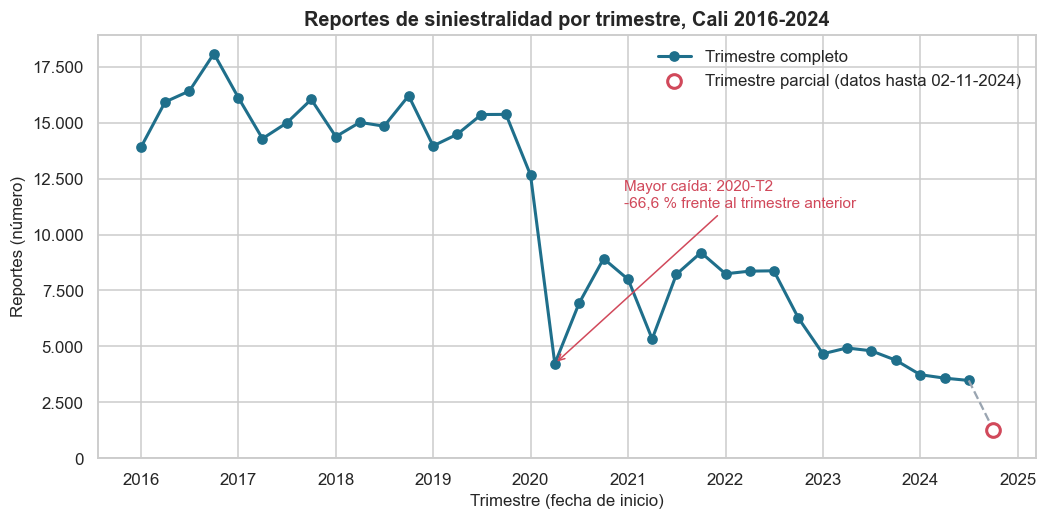

In [3]:
SQL_Q2 = """
-- Q2
SELECT
    f.anio,
    f.trimestre,
    COUNT(*) AS total_siniestros,
    LAG(COUNT(*)) OVER (ORDER BY f.anio, f.trimestre) AS trimestre_anterior,
    ROUND(
        100.0 * (COUNT(*) - LAG(COUNT(*)) OVER (ORDER BY f.anio, f.trimestre))
        / NULLIF(LAG(COUNT(*)) OVER (ORDER BY f.anio, f.trimestre), 0), 2
    ) AS variacion_pct
FROM hecho_siniestralidad h
JOIN dim_fecha f ON h.id_fecha = f.id_fecha
GROUP BY f.anio, f.trimestre
ORDER BY f.anio, f.trimestre;
"""

df_q2 = consulta(SQL_Q2)
df_q2["inicio"] = pd.to_datetime(dict(year=df_q2["anio"], month=(df_q2["trimestre"] - 1) * 3 + 1, day=1))
df_q2["periodo"] = df_q2["anio"].astype(str) + "-T" + df_q2["trimestre"].astype(str)
# Un trimestre es parcial si la bodega termina antes de su último día.
df_q2["parcial"] = (df_q2["inicio"] + pd.offsets.QuarterEnd(0)) > FECHA_MAX

completos = df_q2[~df_q2["parcial"]]
parciales = df_q2[df_q2["parcial"]]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(completos["inicio"], completos["total_siniestros"], marker="o", lw=2,
        color=COLOR_PRINCIPAL, label="Trimestre completo")
if len(parciales):
    ax.plot([completos.iloc[-1]["inicio"], parciales.iloc[0]["inicio"]],
            [completos.iloc[-1]["total_siniestros"], parciales.iloc[0]["total_siniestros"]],
            ls="--", color=COLOR_NEUTRO)
    ax.scatter(parciales["inicio"], parciales["total_siniestros"], s=80, zorder=3,
               facecolors="white", edgecolors=COLOR_ALERTA, linewidths=2,
               label=f"Trimestre parcial (datos hasta {FECHA_MAX:%d-%m-%Y})")

caida = completos.loc[completos["variacion_pct"].idxmin()]
ax.annotate(f"Mayor caída: {caida['periodo']}\n{pct(caida['variacion_pct'])} frente al trimestre anterior",
            xy=(caida["inicio"], caida["total_siniestros"]),
            xytext=(caida["inicio"] + pd.Timedelta(days=260), caida["total_siniestros"] + 7000),
            arrowprops=dict(arrowstyle="->", color=COLOR_ALERTA), color=COLOR_ALERTA, fontsize=10)

ax.set_title("Reportes de siniestralidad por trimestre, Cali 2016-2024")
ax.set_xlabel("Trimestre (fecha de inicio)")
ax.set_ylabel("Reportes (número)")
ax.yaxis.set_major_formatter(FMT_MILES)
ax.set_ylim(bottom=0)
ax.legend(loc="upper right")
guardar(fig, "v1_serie_trimestral")


**Insight:** entre 2016 y 2019 el volumen trimestral se mantuvo entre unos 13.900 y 18.100 reportes; en
2020-T2 cae a unos 4.200 (cerca de −67 % frente al trimestre anterior) y no se recupera: desde 2023 oscila entre
3.500 y 4.900. Como el nivel sigue bajando en 2022-2024, no se explica solo por la pandemia, y la Fase B documenta
un cambio de cobertura del registro, así que la serie debe leerse como un cambio en cómo se reporta y no como una
mejora de la seguridad vial. El último punto (2024-T4) es parcial porque los datos terminan el 2 de noviembre.

## Visualización 2 — Variación porcentual trimestral (serie de tiempo)

**Pregunta de negocio:** ¿Qué trimestres concentran los cambios más bruscos y hay un patrón estacional?
*(Consulta 2 de la Fase C, columna `variacion_pct`.)*

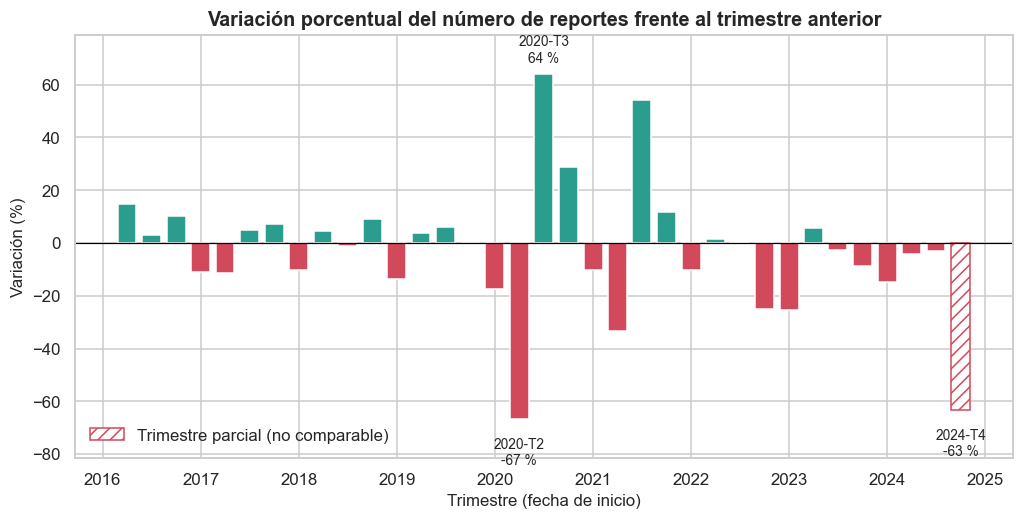

In [4]:
var = df_q2.dropna(subset=["variacion_pct"])
fig, ax = plt.subplots(figsize=(11, 5))
colores = np.where(var["variacion_pct"] >= 0, COLOR_OK, COLOR_ALERTA)
ax.bar(var["inicio"], var["variacion_pct"], width=70, color=colores)

parcial_var = var[var["parcial"]]
if len(parcial_var):
    ax.bar(parcial_var["inicio"], parcial_var["variacion_pct"], width=70, color="white",
           edgecolor=COLOR_ALERTA, hatch="///", label="Trimestre parcial (no comparable)")
    ax.legend(loc="lower left")

for _, fila in var[var["variacion_pct"].abs() >= 60].iterrows():
    ax.annotate(f"{fila['periodo']}\n{pct(fila['variacion_pct'], 0)}",
                xy=(fila["inicio"], fila["variacion_pct"]),
                xytext=(0, 8 if fila["variacion_pct"] > 0 else -30),
                textcoords="offset points", ha="center", fontsize=9)

ax.axhline(0, color="black", lw=0.8)
ax.set_title("Variación porcentual del número de reportes frente al trimestre anterior")
ax.set_xlabel("Trimestre (fecha de inicio)")
ax.set_ylabel("Variación (%)")
ax.set_ylim(var["variacion_pct"].min() - 15, var["variacion_pct"].max() + 15)
guardar(fig, "v2_variacion_trimestral")


**Insight:** los dos extremos son 2020-T2 (cerca de −67 %) y su rebote en 2020-T3 (cerca de +64 %); el otro valor
extremo, 2024-T4, es un artefacto del corte de datos y no una caída real. Sin ellos, casi todas las variaciones
quedan entre −15 % y +15 %, y en 2017-2019 el primer trimestre cae entre 10 % y 14 % cada año, un patrón estacional
moderado que sí es interpretable. Los saltos grandes de 2020 y 2023 no son estacionalidad: reflejan el cambio de
cobertura del registro.

## Visualización 3 — Reportes por tipo de accidente, todas las categorías (comparación categórica)

**Pregunta de negocio:** ¿Qué parte de los reportes corresponde realmente a un accidente con tipo registrado?
*(Consulta 1 de la Fase C.)*

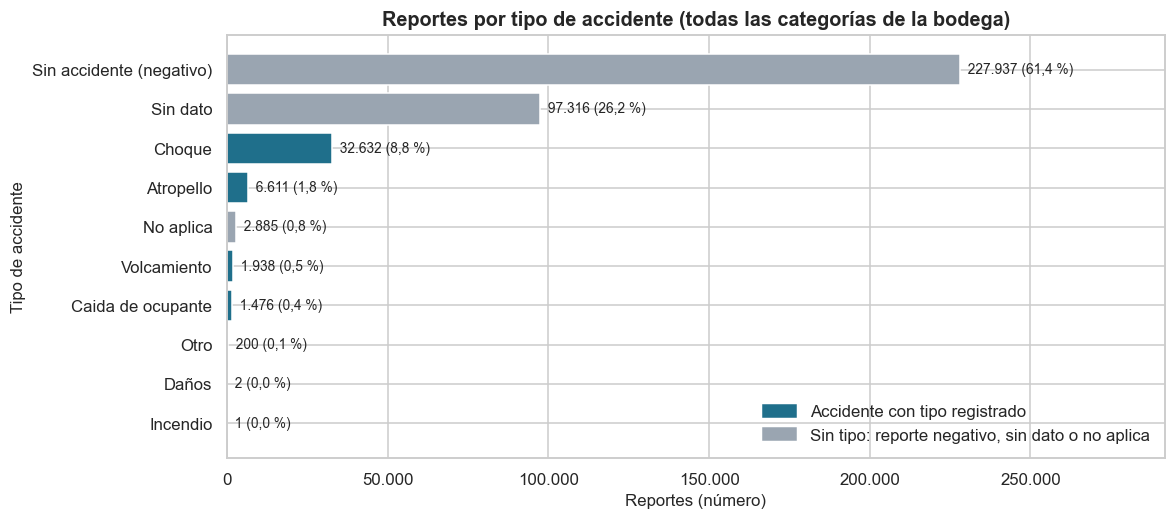

Reportes con tipo registrado: 42.860 de 370.998


In [5]:
SQL_Q1 = """
-- Q1
SELECT
    ta.tipo_accidente,
    COUNT(*) AS total_siniestros,
    ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS porcentaje_total
FROM hecho_siniestralidad h
JOIN dim_tipo_accidente ta ON h.id_tipo_accidente = ta.id_tipo_accidente
GROUP BY ta.tipo_accidente
ORDER BY total_siniestros DESC
LIMIT 10;
"""

df_q1 = consulta(SQL_Q1)
df_q1["categoria"] = df_q1["tipo_accidente"].map(etiqueta)
df_q1["es_centinela"] = df_q1["tipo_accidente"].str.upper().isin(CENTINELAS)

d = df_q1.sort_values("total_siniestros")
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(d["categoria"], d["total_siniestros"],
        color=[COLOR_NEUTRO if c else COLOR_PRINCIPAL for c in d["es_centinela"]])
for y, (v, p) in enumerate(zip(d["total_siniestros"], d["porcentaje_total"])):
    ax.text(v, y, f"  {miles(v)} ({pct(p)})", va="center", fontsize=9)

ax.set_xlim(0, d["total_siniestros"].max() * 1.28)
ax.xaxis.set_major_formatter(FMT_MILES)
ax.set_title("Reportes por tipo de accidente (todas las categorías de la bodega)")
ax.set_xlabel("Reportes (número)")
ax.set_ylabel("Tipo de accidente")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR_PRINCIPAL),
                   plt.Rectangle((0, 0), 1, 1, color=COLOR_NEUTRO)],
          labels=["Accidente con tipo registrado", "Sin tipo: reporte negativo, sin dato o no aplica"],
          loc="lower right")
guardar(fig, "v3_tipo_accidente_todas")

sin_tipo = df_q1.loc[df_q1["es_centinela"], "total_siniestros"].sum()
print(f"Reportes con tipo registrado: {miles(df_q1.loc[~df_q1['es_centinela'], 'total_siniestros'].sum())} "
      f"de {miles(df_q1['total_siniestros'].sum())}")


**Insight:** solo cerca del 12 % de los reportes (unos 42.900 de 371.000) corresponde a un accidente con tipo
registrado. El 61 % son reportes negativos (sin accidente), el 26 % no tiene tipo y menos del 1 % dice «No aplica».
La base es, ante todo, un registro de reportes recibidos y no un conteo de accidentes confirmados, y cualquier
cifra de «siniestros» calculada sobre todas las filas mezcla ambas cosas.

## Visualización 4 — Accidentes con tipo registrado (comparación categórica)

**Pregunta de negocio:** entre los accidentes cuyo tipo sí se registró, ¿cuáles son los más frecuentes?
*(Consulta 1 de la Fase C, sin las categorías centinela.)*

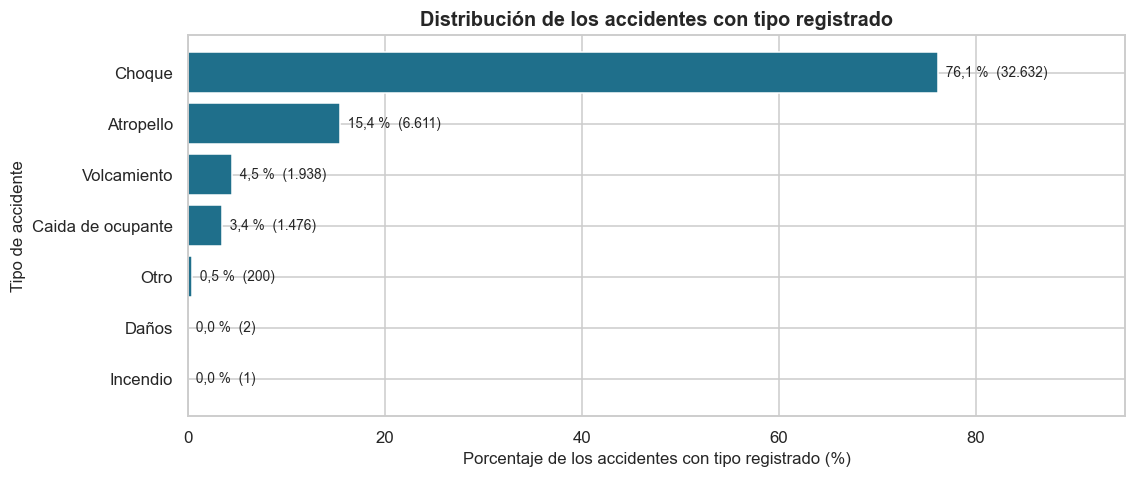

In [7]:
tipados = df_q1[~df_q1["es_centinela"]].copy()
tipados["pct_tipados"] = 100 * tipados["total_siniestros"] / tipados["total_siniestros"].sum()
d = tipados.sort_values("total_siniestros")

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(d["categoria"], d["pct_tipados"], color=COLOR_PRINCIPAL)
for y, (n, p) in enumerate(zip(d["total_siniestros"], d["pct_tipados"])):
    ax.text(p, y, f"  {pct(p)}  ({miles(n)})", va="center", fontsize=9)

ax.set_xlim(0, d["pct_tipados"].max() * 1.25)
ax.set_title("Distribución de los accidentes con tipo registrado")
ax.set_xlabel("Porcentaje de los accidentes con tipo registrado (%)")
ax.set_ylabel("Tipo de accidente")
guardar(fig, "v4_tipo_accidente_tipados")


**Insight:** entre los accidentes con tipo registrado el choque concentra cerca de tres de cada cuatro (≈ 76 %) y
el atropello otro 15 %; volcamiento y caída de ocupante suman alrededor del 8 % y el resto es marginal. Priorizar
la prevención de choques cubre la mayor parte de los eventos tipificados, mientras que el atropello, con menos
volumen, merece seguimiento aparte por involucrar a peatones. Esta lectura solo vale para el 12 % de los reportes
que tiene tipo (visualización 3).

## Visualización 5 — Medio de reporte predominante por año (comparación categórica en el tiempo)

**Pregunta de negocio:** ¿el campo «medio de reporte» es comparable entre años?
*(Consulta 6 de la Fase C, contrastada con los totales anuales de la Consulta 2.)*

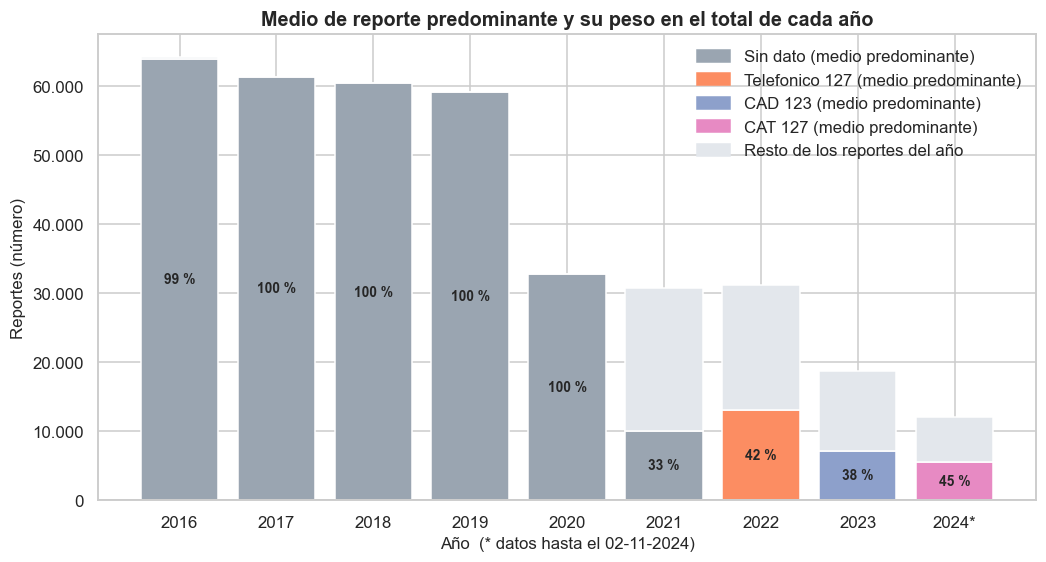

In [8]:
SQL_Q6 = """
-- Q6
WITH por_anio AS (
    SELECT
        f.anio,
        mr.medio_reporte,
        COUNT(*) AS total_siniestros,
        ROW_NUMBER() OVER (PARTITION BY f.anio ORDER BY COUNT(*) DESC) AS rn
    FROM hecho_siniestralidad h
    JOIN dim_fecha f ON h.id_fecha = f.id_fecha
    JOIN dim_medio_reporte mr ON h.id_medio_reporte = mr.id_medio_reporte
    GROUP BY f.anio, mr.medio_reporte
)
SELECT anio, medio_reporte AS medio_predominante, total_siniestros
FROM por_anio
WHERE rn = 1
ORDER BY anio;
"""

df_q6 = consulta(SQL_Q6)
anual = df_q2.groupby("anio")["total_siniestros"].sum().rename("total_anual")
d = df_q6.set_index("anio").join(anual)
d["resto"] = d["total_anual"] - d["total_siniestros"]
d["pct"] = 100 * d["total_siniestros"] / d["total_anual"]
d["medio"] = d["medio_predominante"].map(etiqueta)

medios = list(dict.fromkeys(d["medio"]))
paleta = dict(zip(medios, sns.color_palette("Set2", len(medios))))
paleta["Sin dato"] = COLOR_NEUTRO
x = [f"{a}*" if (a == FECHA_MAX.year and FECHA_MAX < pd.Timestamp(year=a, month=12, day=31)) else str(a)
     for a in d.index]

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(x, d["total_siniestros"], color=[paleta[m] for m in d["medio"]])
ax.bar(x, d["resto"], bottom=d["total_siniestros"], color=COLOR_SUAVE)
for i, (_, fila) in enumerate(d.iterrows()):
    ax.text(i, fila["total_siniestros"] / 2, pct(fila["pct"], 0), ha="center", va="center",
            fontsize=9, fontweight="bold")

leyenda = [plt.Rectangle((0, 0), 1, 1, color=paleta[m]) for m in medios]
leyenda.append(plt.Rectangle((0, 0), 1, 1, color=COLOR_SUAVE))
ax.legend(leyenda, [f"{m} (medio predominante)" for m in medios] + ["Resto de los reportes del año"],
          loc="upper right")
ax.yaxis.set_major_formatter(FMT_MILES)
ax.set_title("Medio de reporte predominante y su peso en el total de cada año")
ax.set_xlabel("Año  (* datos hasta el " + f"{FECHA_MAX:%d-%m-%Y})")
ax.set_ylabel("Reportes (número)")
guardar(fig, "v5_medio_predominante_anual")


**Insight:** hasta 2020 prácticamente el 100 % de los reportes no trae medio de reporte (99,5 % en 2016); solo desde
2021 el campo empieza a llenarse y aparecen canales como Telefónico 127 (2022), CAD 123 (2023) y CAT 127 (2024). Aun
en 2024 el medio predominante cubre menos de la mitad de los reportes (≈ 45 %). El campo no permite comparar canales
entre años, y el momento en que empieza a llenarse coincide con la caída de volumen de la visualización 1, lo que
apunta a un cambio en el sistema de registro.

## Visualización 6 — Promedio de vehículos vs. proporción multivehículo (relación bivariada)

**Pregunta de negocio:** ¿qué combinaciones de vehículos se asocian con más eventos multivehículo?
*(Consulta 5 de la Fase C; solo reportes con `numero_vehiculos` informado.)*

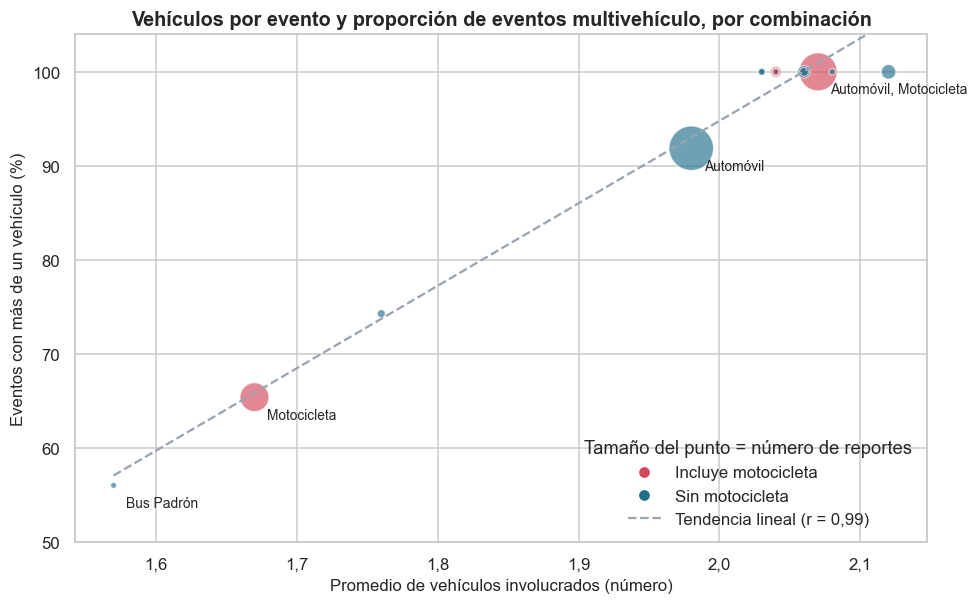

Combinaciones analizadas: 14
Correlación promedio vs, multivehículo: r = 0,99


In [9]:
SQL_Q5 = """
-- Q5
-- La dimensión puede conservar repeticiones del mismo tipo (p. ej. AUTOMOVIL,
-- AUTOMOVIL). Para que la combinación represente TIPOS distintos de vehículo,
-- se canoniza cada reporte eliminando duplicados dentro de la lista.
WITH base AS (
    SELECT
        h.numero_vehiculos,
        (
            SELECT string_agg(DISTINCT trim(u.tipo), ', ' ORDER BY trim(u.tipo))
            FROM unnest(string_to_array(v.tipos_vehiculos, ',')) AS u(tipo)
            WHERE trim(u.tipo) <> ''
        ) AS tipos_vehiculos
    FROM hecho_siniestralidad h
    JOIN dim_vehiculos_implicados v
      ON h.id_vehiculos_implicados = v.id_vehiculos_implicados
    WHERE h.numero_vehiculos IS NOT NULL
),
agrupado AS (
    SELECT
        tipos_vehiculos,
        COUNT(*) AS total_siniestros,
        ROUND(AVG(numero_vehiculos), 2) AS promedio_vehiculos,
        SUM(CASE WHEN numero_vehiculos > 1 THEN 1 ELSE 0 END) AS siniestros_multivehiculo,
        ROUND(
            100.0 * SUM(CASE WHEN numero_vehiculos > 1 THEN 1 ELSE 0 END) / COUNT(*),
            2
        ) AS pct_multivehiculo
    FROM base
    WHERE tipos_vehiculos IS NOT NULL
      AND UPPER(tipos_vehiculos) NOT IN ('DESCONOCIDO', 'SIN ACCIDENTE (NEGATIVO)', 'NO APLICA')
    GROUP BY tipos_vehiculos
    HAVING COUNT(*) >= 30
)
SELECT
    tipos_vehiculos,
    total_siniestros,
    promedio_vehiculos,
    siniestros_multivehiculo,
    pct_multivehiculo
FROM agrupado
ORDER BY total_siniestros DESC
LIMIT 14;
"""

df_q5 = consulta(SQL_Q5)

q5 = df_q5.copy()
q5["combinacion"] = q5["tipos_vehiculos"].map(etiqueta_vehiculo)
q5["con_moto"] = q5["tipos_vehiculos"].str.upper().str.contains("MOTOCICLETA", na=False)

r = q5["promedio_vehiculos"].corr(q5["pct_multivehiculo"])
pendiente, origen = np.polyfit(q5["promedio_vehiculos"], q5["pct_multivehiculo"], 1)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(
    q5["promedio_vehiculos"],
    q5["pct_multivehiculo"],
    s=q5["total_siniestros"] / 60,
    c=[COLOR_ALERTA if m else COLOR_PRINCIPAL for m in q5["con_moto"]],
    alpha=0.65,
    edgecolors="white",
    linewidths=0.8,
)

xs = np.linspace(q5["promedio_vehiculos"].min(), q5["promedio_vehiculos"].max(), 50)
ax.plot(
    xs,
    pendiente * xs + origen,
    ls="--",
    color=COLOR_NEUTRO,
    label=f"Tendencia lineal (r = {r:.2f})".replace(".", ","),
)

# Etiquetas seleccionadas para reproducir la lectura del informe y evitar solapamientos.
for nombre in ["Bus Padrón", "Motocicleta", "Automóvil", "Automóvil, Motocicleta"]:
    fila = q5[q5["combinacion"] == nombre]
    if not fila.empty:
        x0, y0 = fila.iloc[0]["promedio_vehiculos"], fila.iloc[0]["pct_multivehiculo"]
        ax.annotate(nombre, (x0, y0), xytext=(8, -14), textcoords="offset points", fontsize=9)

ax.set_title("Vehículos por evento y proporción de eventos multivehículo, por combinación")
ax.set_xlabel("Promedio de vehículos involucrados (número)")
ax.set_ylabel("Eventos con más de un vehículo (%)")
ax.set_ylim(50, 104)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ",")))
ax.legend(
    handles=[
        plt.Line2D([], [], marker="o", ls="", color=COLOR_ALERTA, label="Incluye motocicleta"),
        plt.Line2D([], [], marker="o", ls="", color=COLOR_PRINCIPAL, label="Sin motocicleta"),
        plt.Line2D([], [], ls="--", color=COLOR_NEUTRO, label=f"Tendencia lineal (r = {r:.2f})".replace(".", ",")),
    ],
    loc="lower right",
    title="Tamaño del punto = número de reportes",
)
guardar(fig, "v6_vehiculos_bivariada")

print(f"Combinaciones analizadas: {len(q5)}")
print(f"Correlación promedio vs. multivehículo: r = {r:.2f}".replace(".", ","))


**Insight:** existe una relación casi lineal entre el promedio de vehículos y la proporción de eventos multivehículo (r ≈ 0,99). Las combinaciones con dos o más tipos de vehículo llegan al 100 %, mientras que la motocicleta sola registra 65,4 % y el bus padrón 56,0 %. Parte de la relación es mecánica: dos tipos distintos implican al menos dos vehículos; por eso la lectura útil está en los tipos únicos y, entre los de mayor volumen, la motocicleta es la que más aparece en eventos de un solo vehículo.


### Validación contra el informe
Las visualizaciones 6 y 7 deben construirse sobre la **combinación canónica de tipos de vehículo**: se eliminan repeticiones del mismo tipo dentro de cada reporte (por ejemplo, `AUTOMOVIL, AUTOMOVIL` cuenta como `Automóvil`). Esto evita dividir el volumen de una misma combinación en varias categorías y corrige los valores que no coincidían con la Figura 5 y la Figura 6 del informe. La consulta conserva únicamente las 14 combinaciones con mayor volumen, después de canonizar y excluir categorías centinela.


## Visualización 7 — Combinaciones de vehículos más frecuentes (comparación categórica)

**Pregunta de negocio:** ¿qué combinaciones de vehículos aparecen con más frecuencia y cuánto pesa la motocicleta?
*(Consulta 5 de la Fase C.)*

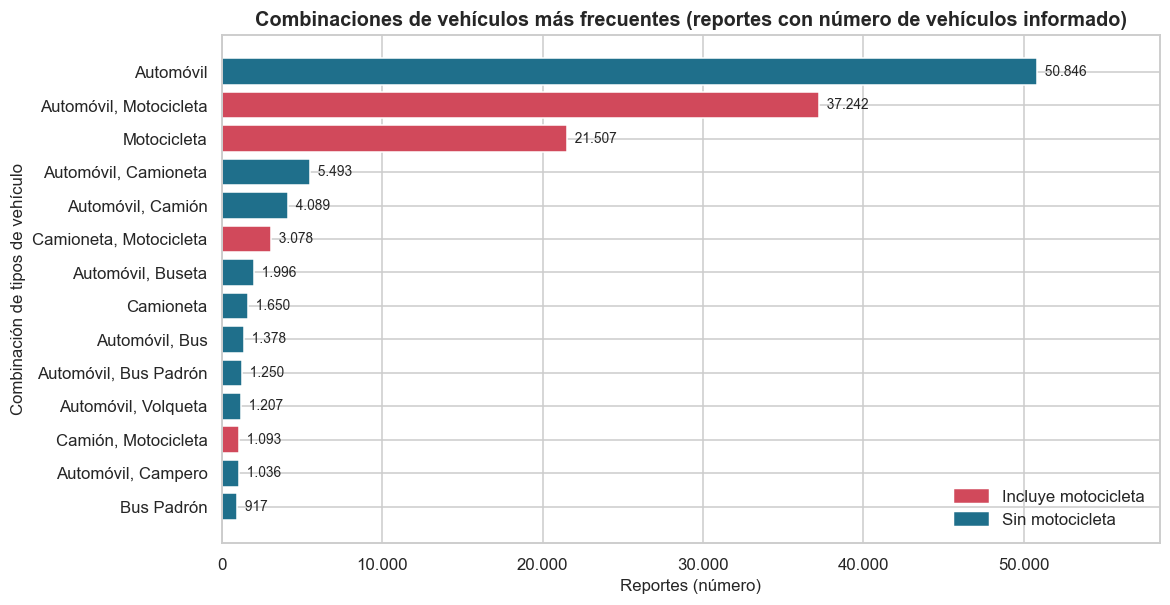

Combinaciones con motocicleta: 62.920 de 176.577 reportes con número de vehículos informado (35,6 %)
Las dos combinaciones más frecuentes suman 49,9 % de esa base


In [10]:
d = q5.sort_values("total_siniestros")

# Base: todos los reportes que informan numero_vehiculos.
SQL_BASE = """
-- BASE
SELECT COUNT(*) AS n
FROM hecho_siniestralidad
WHERE numero_vehiculos IS NOT NULL;
"""
base_informada = int(consulta(SQL_BASE).loc[0, "n"])

fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(
    d["combinacion"],
    d["total_siniestros"],
    color=[COLOR_ALERTA if m else COLOR_PRINCIPAL for m in d["con_moto"]],
)
for y, v in enumerate(d["total_siniestros"]):
    ax.text(v, y, f"  {miles(v)}", va="center", fontsize=9)

ax.set_xlim(0, d["total_siniestros"].max() * 1.15)
ax.xaxis.set_major_formatter(FMT_MILES)
ax.set_title("Combinaciones de vehículos más frecuentes (reportes con número de vehículos informado)")
ax.set_xlabel("Reportes (número)")
ax.set_ylabel("Combinación de tipos de vehículo")
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_ALERTA),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_PRINCIPAL),
    ],
    labels=["Incluye motocicleta", "Sin motocicleta"],
    loc="lower right",
)
guardar(fig, "v7_combinaciones_vehiculos")

moto = q5.loc[q5["con_moto"], "total_siniestros"].sum()
top2 = q5.nlargest(2, "total_siniestros")["total_siniestros"].sum()

print(
    f"Combinaciones con motocicleta: {miles(moto)} de {miles(base_informada)} reportes "
    f"con número de vehículos informado ({pct(100 * moto / base_informada)})"
)
print(f"Las dos combinaciones más frecuentes suman {pct(100 * top2 / base_informada)} de esa base")


**Insight:** el automóvil solo (50.846 reportes) y la combinación automóvil + motocicleta (37.242) reúnen el 49,9 % de los reportes con número de vehículos informado. Las combinaciones que incluyen motocicleta suman al menos 62.920 reportes (35,6 %) dentro de esa base. Como `numero_vehiculos` falta en el 52,4 % de los reportes, estas cifras describen únicamente los reportes que informan ese campo.


## Visualización 8 — Distribución de reportes por trimestre (distribución univariada)

**Pregunta de negocio:** ¿existe un nivel «típico» de reportes por trimestre?
*(Consulta 2 de la Fase C, solo trimestres completos.)*

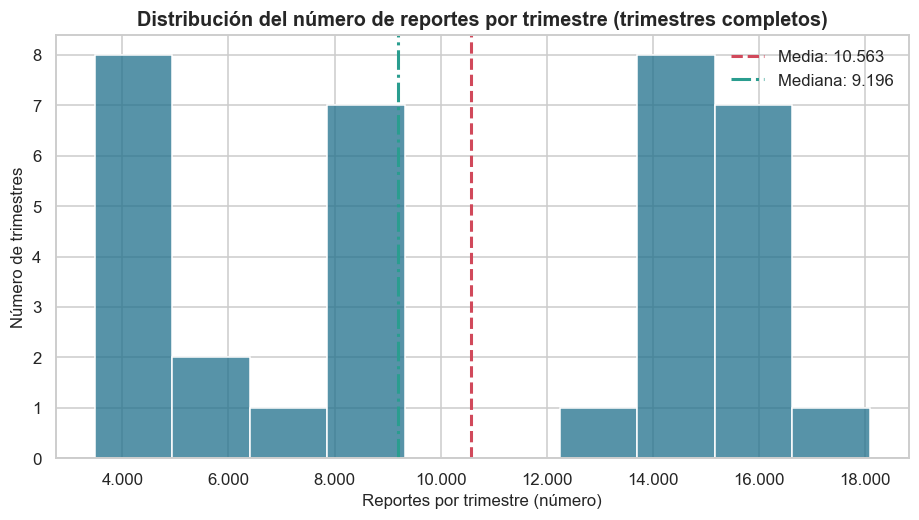

Trimestres completos: 35 | mínimo 3.479 | máximo 18.088 | media 10.563


In [11]:
tot = df_q2.loc[~df_q2["parcial"], "total_siniestros"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(tot, bins=10, color=COLOR_PRINCIPAL, edgecolor="white", ax=ax)
ax.axvline(tot.mean(), color=COLOR_ALERTA, ls="--", lw=2, label=f"Media: {miles(tot.mean())}")
ax.axvline(tot.median(), color=COLOR_OK, ls="-.", lw=2, label=f"Mediana: {miles(tot.median())}")
ax.xaxis.set_major_formatter(FMT_MILES)
ax.set_title("Distribución del número de reportes por trimestre (trimestres completos)")
ax.set_xlabel("Reportes por trimestre (número)")
ax.set_ylabel("Número de trimestres")
ax.legend()
guardar(fig, "v8_distribucion_trimestral")

print(f"Trimestres completos: {len(tot)} | mínimo {miles(tot.min())} | máximo {miles(tot.max())} | media {miles(tot.mean())}")


**Insight:** la distribución es bimodal: 17 trimestres completos están entre 12.600 y 18.100 reportes y 18 están por debajo de 9.300, sin trimestres en el intervalo intermedio. La media queda alrededor de 10.600 y cae en ese hueco, así que no representa un nivel trimestral típico. La lectura correcta es la coexistencia de dos regímenes de registro, no una tendencia gradual.


## Notas de lectura

- **2024 está incompleto** (datos hasta el 2 de noviembre): no se compara con años completos.
- **Reportes, no accidentes:** solo cerca del 12 % de las filas tiene un tipo de accidente registrado (visualización 3).
- **Cambio de cobertura:** la caída de 81 % entre 2016 y 2024, el vacío de `medio_reporte` hasta 2020 y la
  bimodalidad de la visualización 8 apuntan a un cambio en el registro. Conviene validarlo con la entidad fuente
  antes de leer cualquiera de estas series como tendencia de seguridad vial.
- Las figuras quedan guardadas en `entrega/figuras/` y alimentan el informe (`entrega/informe.pdf`).
